# Harris Corner Detector (Harris & Stephens, 1988)

**INF605 Fundamentals of Image Processing – Group 15**

Eren Şimşek, Mert Oğuz Mirzaoğlu, Muhammet Şimşek, Ahmetcan Karabulut, Yunus Emre Erdoğan

Reference: C. Harris and M. Stephens, "A combined corner and edge detector," *Proc. 4th Alvey Vision Conference*, 1988, pp. 147–151.

## 0. Setup

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import cv2
from pathlib import Path

DATA_DIR = Path("data")
RESULTS_DIR = Path("results")
RESULTS_DIR.mkdir(exist_ok=True)

plt.rcParams["figure.figsize"] = (8, 6)

## 1. Loading the test images

We work on grayscale images stored as `float64` in the range [0, 1]. Working in float is important here: the
gradients can be negative and the products $I_x^2$, $I_xI_y$ would overflow in `uint8`.

Test images in `data/`:
- `shapes.png`: a synthetic scene we drew ourselves. It has flat regions, straight edges, sharp corners and a circle (curved edge, no corners), so it is easy to check whether the detector responds in the right places.
- `checkerboard.png`: regular grid of corners, from `skimage.data`.
- `camera.png`: a natural image, from `skimage.data`.

Our own photo pairs (same scene from two viewpoints) will be added for the matching experiment.

In [2]:
def load_gray(path):
    """Read an image as grayscale float64 in [0, 1]."""
    img = cv2.imread(str(path), cv2.IMREAD_GRAYSCALE)
    if img is None:
        raise FileNotFoundError(f"could not read {path}")
    return img.astype(np.float64) / 255.0


def show_images(images, titles, cmap="gray", size=4):
    fig, axes = plt.subplots(1, len(images), figsize=(size * len(images), size))
    if len(images) == 1:
        axes = [axes]
    for ax, img, title in zip(axes, images, titles):
        ax.imshow(img, cmap=cmap)
        ax.set_title(title)
        ax.axis("off")
    plt.tight_layout()
    plt.show()

shapes.png         shape=(256, 256)  dtype=float64  min=0.24  max=0.90
checkerboard.png   shape=(200, 200)  dtype=float64  min=0.00  max=1.00
camera.png         shape=(512, 512)  dtype=float64  min=0.00  max=1.00


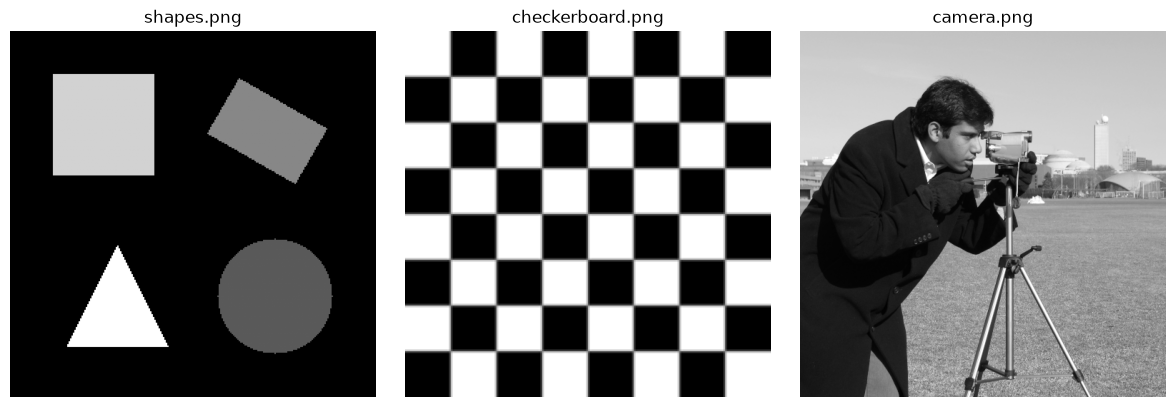

In [3]:
names = ["shapes.png", "checkerboard.png", "camera.png"]
images = {name: load_gray(DATA_DIR / name) for name in names}

for name, img in images.items():
    print(f"{name:18s} shape={img.shape}  dtype={img.dtype}  min={img.min():.2f}  max={img.max():.2f}")

show_images(list(images.values()), names)

## 2. Image gradients (Sobel)

The Harris detector looks at how the intensity changes when a small window is shifted. After a first order
Taylor expansion this only needs the image derivatives $I_x = \partial I / \partial x$ and $I_y = \partial I / \partial y$.

We estimate them with the Sobel operator (Gonzalez & Woods, Section 3.6):

$$
K_x = \begin{bmatrix} -1 & 0 & 1 \\ -2 & 0 & 2 \\ -1 & 0 & 1 \end{bmatrix}, \qquad
K_y = K_x^T = \begin{bmatrix} -1 & -2 & -1 \\ 0 & 0 & 0 \\ 1 & 2 & 1 \end{bmatrix}
$$

We write the kernels ourselves and only use `cv2.filter2D` for the general filtering operation.
Note that `filter2D` computes **correlation**, not convolution. With the kernels above, correlation gives
$I_x > 0$ when the image gets brighter to the right and $I_y > 0$ when it gets brighter downwards
(row index grows downwards). Borders are handled by reflection so that no false edges appear at the image border.

In [4]:
SOBEL_X = np.array([[-1, 0, 1],
                    [-2, 0, 2],
                    [-1, 0, 1]], dtype=np.float64)
SOBEL_Y = SOBEL_X.T


def image_gradients(img):
    """Return (Ix, Iy) computed with Sobel kernels."""
    ix = cv2.filter2D(img, cv2.CV_64F, SOBEL_X, borderType=cv2.BORDER_REFLECT)
    iy = cv2.filter2D(img, cv2.CV_64F, SOBEL_Y, borderType=cv2.BORDER_REFLECT)
    return ix, iy

**Sanity check.** On a horizontal ramp the intensity grows by the same amount in every column, so $I_x$ should be
constant and $I_y$ should be zero. The Sobel kernel weights add up to 4 on each side ($1+2+1$) and the
difference is taken over 2 pixels, so for a ramp with slope $s$ per pixel we expect $I_x = 8s$.

In [5]:
slope = 0.01
ramp = np.tile(np.arange(50) * slope, (30, 1))
rx, ry = image_gradients(ramp)

inner = (slice(1, -1), slice(1, -1))   # ignore the border pixels
print("Ix inside:", rx[inner].min(), "to", rx[inner].max(), " (expected", 8 * slope, ")")
print("Iy inside:", np.abs(ry[inner]).max())

Ix inside: 0.0799999999999998 to 0.08000000000000007  (expected 0.08 )
Iy inside: 2.220446049250313e-16


Two more checks:
- a constant image has no edges, so both derivatives must be exactly zero;
- `filter2D` should give the same result as writing the Sobel sum by hand with NumPy slicing
  (on the inner pixels, where no padding is involved).

In [6]:
const = np.full((40, 40), 0.7)
cx, cy = image_gradients(const)
print("constant image, max |Ix|, |Iy|:", np.abs(cx).max(), np.abs(cy).max())


def sobel_x_numpy(img):
    """Sobel in x written with slicing, only for the inner pixels."""
    right = img[:-2, 2:] + 2 * img[1:-1, 2:] + img[2:, 2:]
    left = img[:-2, :-2] + 2 * img[1:-1, :-2] + img[2:, :-2]
    return right - left


test = images["camera.png"]
ix_test, _ = image_gradients(test)
diff = np.abs(ix_test[1:-1, 1:-1] - sobel_x_numpy(test)).max()
print("camera.png, max difference filter2D vs NumPy:", diff)

constant image, max |Ix|, |Iy|: 0.0 2.220446049250313e-16
camera.png, max difference filter2D vs NumPy: 8.881784197001252e-16


### Gradients of the test images

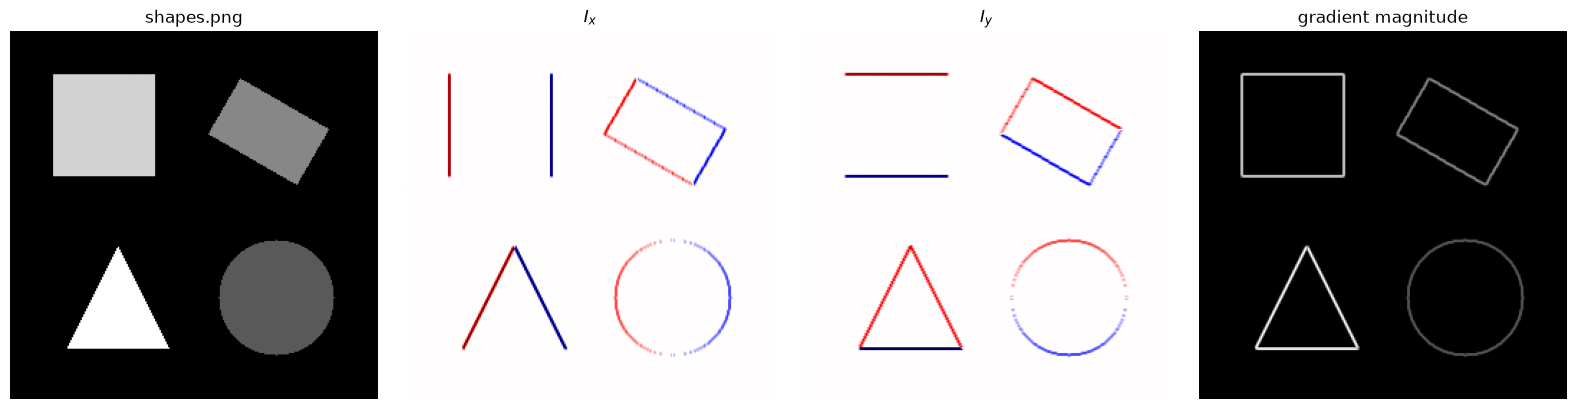

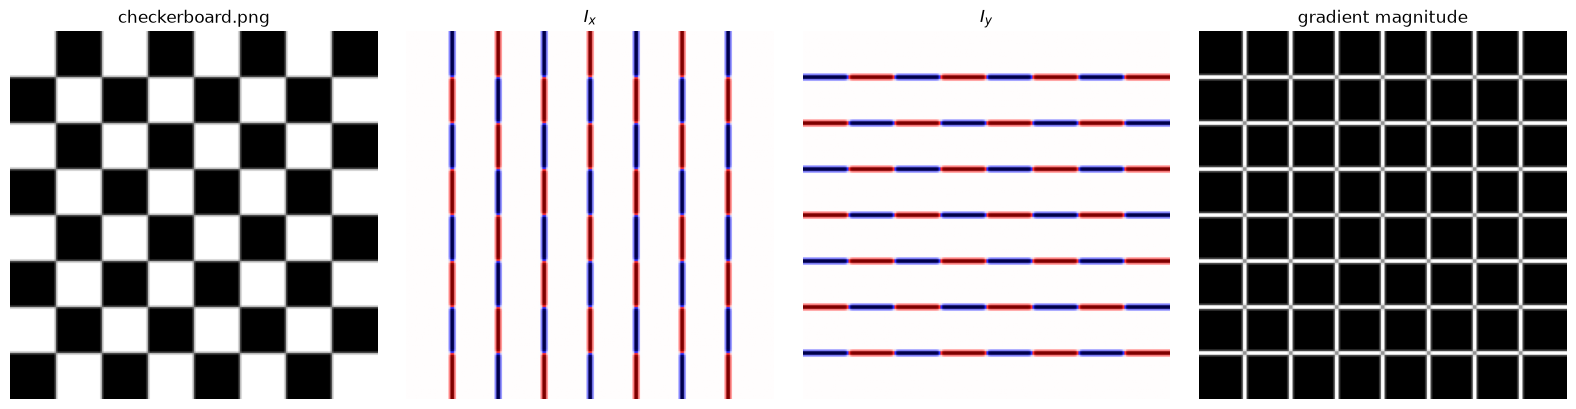

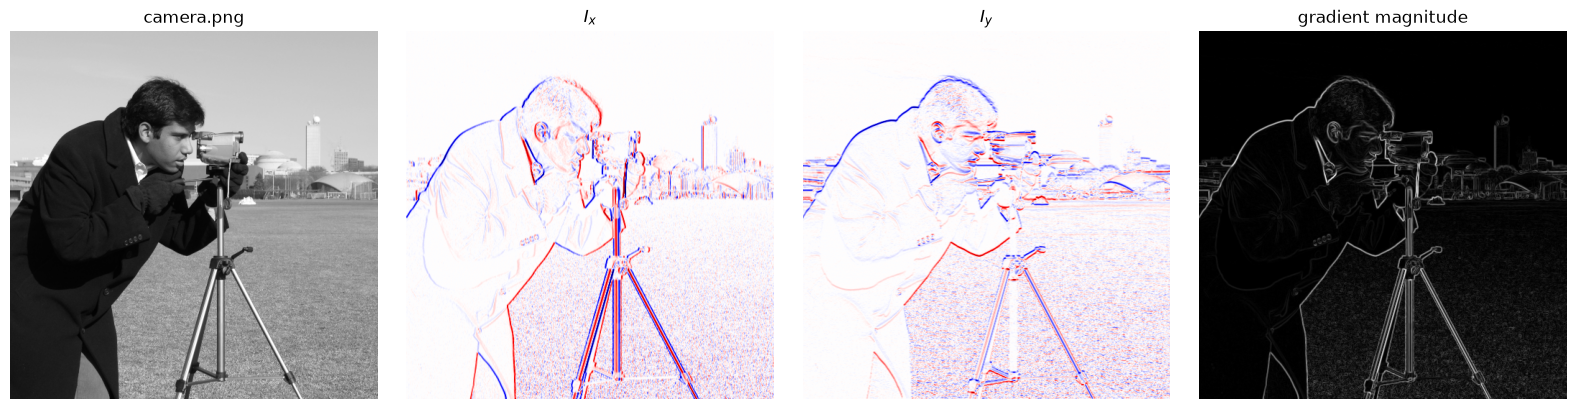

In [7]:
def plot_gradients(img, title):
    ix, iy = image_gradients(img)
    mag = np.hypot(ix, iy)
    lim = np.abs(np.concatenate([ix.ravel(), iy.ravel()])).max()

    fig, axes = plt.subplots(1, 4, figsize=(16, 4))
    axes[0].imshow(img, cmap="gray")
    axes[0].set_title(title)
    axes[1].imshow(ix, cmap="seismic", vmin=-lim, vmax=lim)
    axes[1].set_title("$I_x$")
    axes[2].imshow(iy, cmap="seismic", vmin=-lim, vmax=lim)
    axes[2].set_title("$I_y$")
    axes[3].imshow(mag, cmap="gray")
    axes[3].set_title("gradient magnitude")
    for ax in axes:
        ax.axis("off")
    plt.tight_layout()
    plt.show()
    return ix, iy


gradients = {}
for name, img in images.items():
    gradients[name] = plot_gradients(img, name)

In `shapes.png` the vertical edges of the square only show up in $I_x$ and the horizontal edges only in $I_y$.
At a corner both derivatives are non-zero at the same time. This is exactly what the next step uses: the
structure tensor collects $I_x^2$, $I_y^2$ and $I_xI_y$ in a window around each pixel.

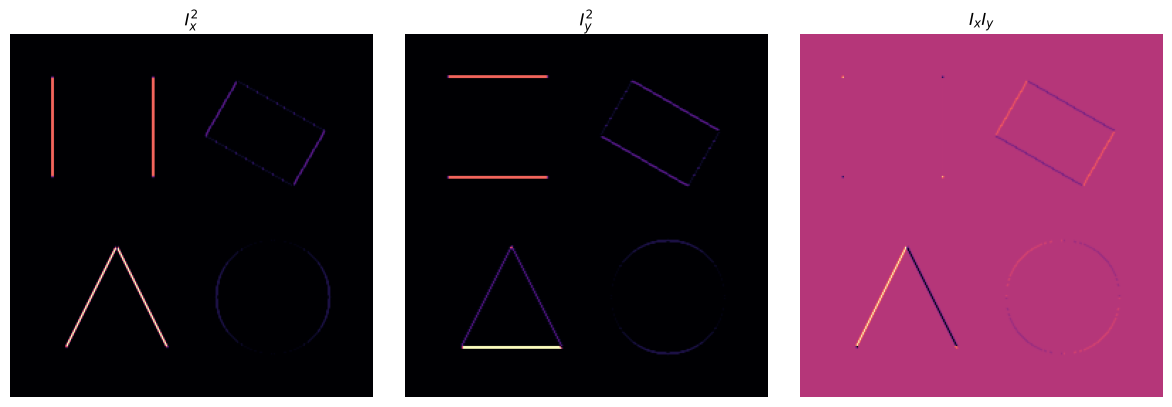

In [8]:
ix, iy = gradients["shapes.png"]
show_images([ix**2, iy**2, ix * iy], ["$I_x^2$", "$I_y^2$", "$I_x I_y$"], cmap="magma")

## 3. Structure tensor with a Gaussian window

## 4. Corner response R

## 5. Thresholding and non-maximum suppression

## 6. Reproducing a result from the paper

## 7. Experiments on our own images: effect of k, sigma and threshold

## 8. Matching corners between two views

## 9. Repeatability under rotation and brightness change

## 10. Comparison with `cv2.cornerHarris`

## 11. Conclusion

## References

1. C. Harris and M. Stephens, "A combined corner and edge detector," *Proc. 4th Alvey Vision Conference*, 1988.
2. R. C. Gonzalez and R. E. Woods, *Digital Image Processing*, 4th ed., Pearson, 2018.